# ДЗ 1.

Пять моделей (item-kNN, iALS, EASE, FM, timeSVD++), сравнение top-10.

Данные (~200 МБ) скачиваются в data/ первой ячейкой. Прогон ~40 мин на CPU.

In [ ]:
!python3.11 -m venv .venv && source .venv/bin/activate
%pip install -r requirements.txt
# !jupyter nbconvert --to notebook --execute --inplace experiments.ipynb

In [1]:
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
import torch

from models.data import download, load_interactions, load_books, k_core, time_split, Split
from models.metrics import evaluate, ndcg_at_k, recall_at_k, Popular
from models.knn import ItemKNN
from models.als import IALS
from models.ease import EASE
from models.fm import FM, item_tokens
from models.timesvdpp import TimeSVDpp

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

MIN_USER, MIN_ITEM = 5, 10     # k-core
VAL_Q, TEST_Q = 0.8, 0.9       # квантили времени
REL_THR = 4                    # релевантно: оценка >= 4
K = 10
N_TRIALS = 15

## 1. Данные

Goodreads Book Graph (UCSD), подмножество Poetry - https://cseweb.ucsd.edu/~jmcauley/datasets/goodreads.html

- goodreads_interactions_poetry.json.gz: user_id, book_id, rating (0-5, 0 - на полке без оценки), is_read, date_added
- goodreads_books_poetry.json.gz: авторы, popular_shelves (пользовательские полки-теги), год, страницы, язык, формат
- goodreads_book_authors.json.gz: авторы

Рекомендуем книги, которые пользователь оценит в будущем. Взаимодействие - оценка (rating > 0), время - date_added. Релевантно - оценка >= 4 в окне оценки.

In [2]:
download("data")
raw = load_interactions("data")
books, authors = load_books("data")
print("взаимодействий:", len(raw), "пользователей:", raw.user_id.nunique(), "книг:", raw.book_id.nunique())
print("книг в метаданных:", len(books))
raw.head()

взаимодействий: 2734350 пользователей: 377799 книг: 36514
книг в метаданных: 36514


,user_id,book_id,rating,is_read,ts
0,8842281e1d1347389f2ab93d60773d4d,1384,4,True,2007-05-09 16:33:44+00:00
1,8842281e1d1347389f2ab93d60773d4d,1376,4,True,2007-05-09 16:33:18+00:00
2,8842281e1d1347389f2ab93d60773d4d,30119,5,True,2007-01-13 21:44:20+00:00
3,72fb0d0087d28c832f15776b0d936598,24769928,0,False,2016-04-27 18:05:51+00:00
4,72fb0d0087d28c832f15776b0d936598,30119,3,True,2012-06-05 01:58:08+00:00


## 2. EDA и подготовка

In [3]:
print("пропуски:\n", raw.isna().sum())
print("\nдубликаты (user, book):", raw.duplicated(["user_id", "book_id"]).sum())
print("пустые даты:", raw.ts.isna().sum(), "| диапазон дат:", raw.ts.min(), "-", raw.ts.max())
print("\nрейтинги:\n", raw.rating.value_counts().sort_index())
print("\nis_read при rating > 0:", raw[raw.rating > 0].is_read.mean().round(3))

пропуски:
 user_id    0
book_id    0
rating     0
is_read    0
ts         0
dtype: int64



дубликаты (user, book): 0
пустые даты: 0 | диапазон дат: 2001-02-13 08:00:00+00:00 - 2017-11-04 05:57:43+00:00

рейтинги:
 rating
0    1505291
1      20497
2      64084
3     237942
4     405565
5     500971
Name: count, dtype: int64

is_read при rating > 0: 1.0


Пропусков и дубликатов нет. 55% строк - rating = 0 (книга на полке, не оценка): отбрасываем. Оценки смещены к 4-5.

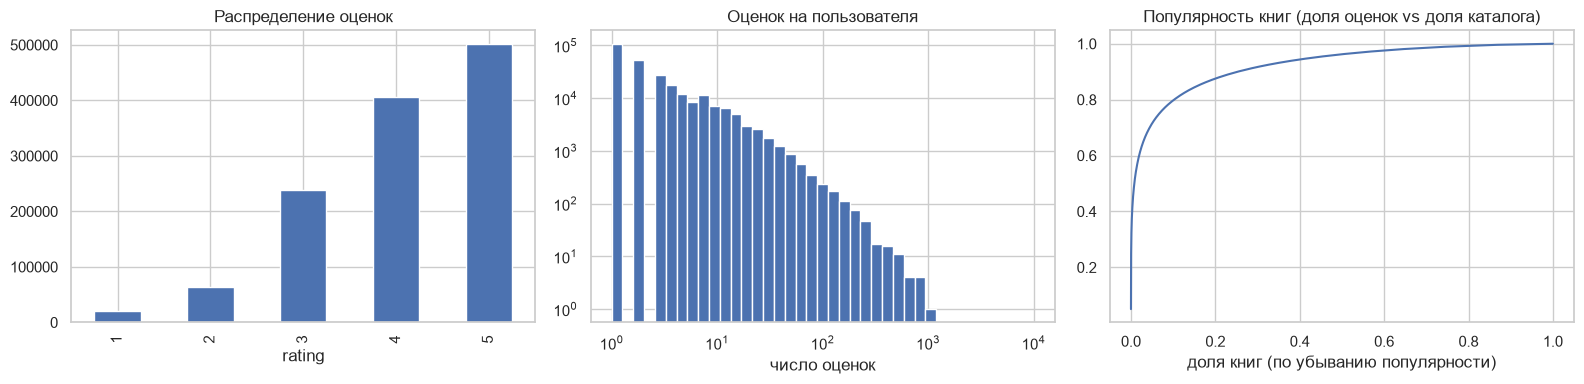

медиана оценок на пользователя: 2.0 | доля пользователей с 1 оценкой: 0.403
топ-1% книг собирают 0.525 оценок
разреженность: 0.9998731660450852


In [4]:
r = raw[raw.rating > 0]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
r.rating.value_counts().sort_index().plot.bar(ax=ax[0], title="Распределение оценок")
uc = r.user_id.value_counts()
ax[1].hist(uc, bins=np.logspace(0, 4, 40)); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Оценок на пользователя"); ax[1].set_xlabel("число оценок")
ic = r.book_id.value_counts().values
ax[2].plot(np.arange(1, len(ic) + 1) / len(ic), np.cumsum(ic) / ic.sum())
ax[2].set_title("Популярность книг (доля оценок vs доля каталога)"); ax[2].set_xlabel("доля книг (по убыванию популярности)")
plt.tight_layout(); plt.show()

print("медиана оценок на пользователя:", uc.median(), "| доля пользователей с 1 оценкой:", (uc == 1).mean().round(3))
print("топ-1% книг собирают", (np.sort(ic)[::-1][:len(ic) // 100].sum() / ic.sum()).round(3), "оценок")
print("разреженность:", 1 - len(r) / (r.user_id.nunique() * r.book_id.nunique()))

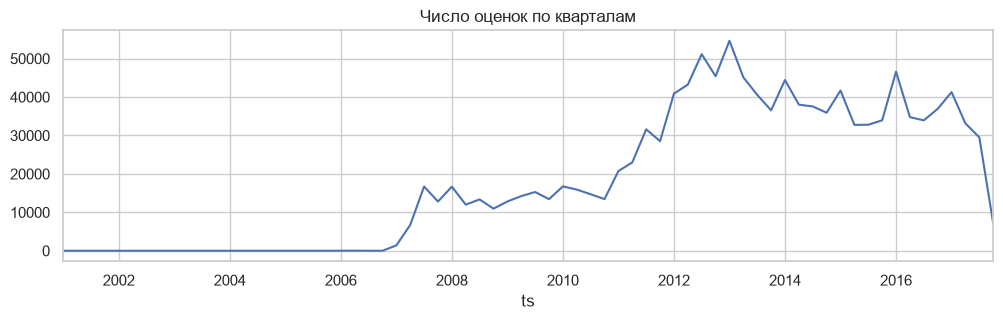

In [5]:
r.set_index("ts").rating.resample("QE").count().plot(figsize=(12, 3), title="Число оценок по кварталам")
plt.show()

Long tail по пользователям и книгам. Основной объём - 2011-2017.

Метаданные:

publication_year   пусто: 0.16 | топ: {'': 5743, '2013': 1700, '2014': 1655, '2015': 1556, '2012': 1530}
num_pages          пусто: 0.20 | топ: {'': 7408, '96': 1277, '80': 1009, '32': 704, '64': 671}
language_code      пусто: 0.53 | топ: {'': 19281, 'eng': 8312, 'ara': 1603, 'per': 916, 'en-US': 864}
format             пусто: 0.19 | топ: {'Paperback': 19945, '': 6950, 'Hardcover': 6659, 'ebook': 885, 'Kindle Edition': 324}
авторов на книгу: {1: 24858, 2: 8097, 3: 2296, 4: 429, 5: 146}


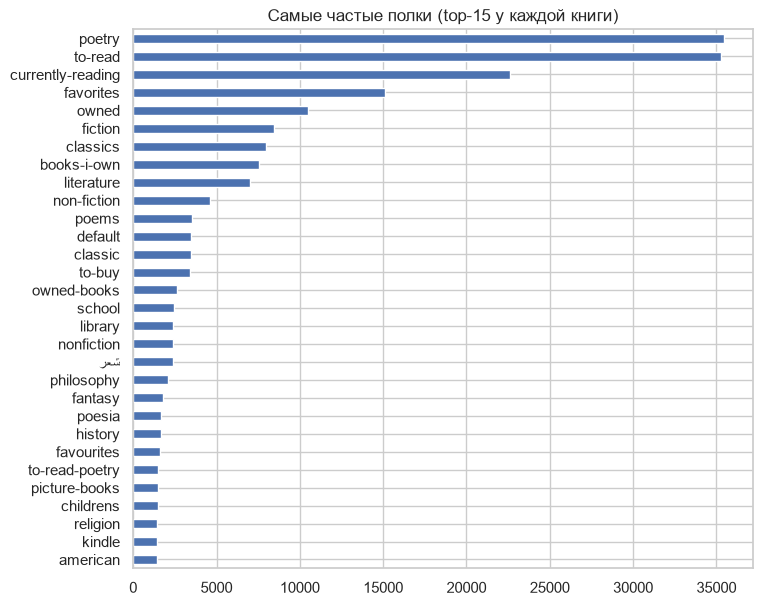

In [6]:
b = books[books.book_id.isin(set(r.book_id))]
for c in ["publication_year", "num_pages", "language_code", "format"]:
    print(f"{c:18s} пусто: {(b[c] == '').mean():.2f} | топ: {b[c].value_counts().head(5).to_dict()}")
print("авторов на книгу:", b.authors.map(len).value_counts().head().to_dict())

import collections
cnt = collections.Counter(x["name"] for sh in b.popular_shelves for x in sh[:15])
pd.Series(dict(cnt.most_common(30))).plot.barh(figsize=(8, 7), title="Самые частые полки (top-15 у каждой книги)")
plt.gca().invert_yaxis(); plt.show()

Авторы есть у всех книг, год/страницы/формат - у 80-85%, язык - у половины. Полки - смесь статусов (to-read, owned, read-in-2016) и жанров (classics, philosophy); для FM статусы отфильтруем. average_rating и ratings_count не используем - они посчитаны с учётом будущего.

Очистка: rating > 0, затем итеративный k-core (пользователь >= 5 оценок, книга >= 10). Убирает пользователей без истории и делает каталог ~10 тыс. книг, чтобы item-item матрицы влезали в память. Детерминированно.

In [7]:
df = k_core(r, MIN_USER, MIN_ITEM)
n_u, n_i = df.user_id.nunique(), df.book_id.nunique()
print(f"было: {len(raw)} строк, после rating>0: {len(r)}, после k-core: {len(df)}")
print(f"пользователей: {n_u}, книг: {n_i}, разреженность: {1 - len(df) / n_u / n_i:.5f}")
assert 100_000 <= len(df) <= 2_000_000 and n_u >= 1000 and n_i >= 1000

было: 2734350 строк, после rating>0: 1229059, после k-core: 758714
пользователей: 57672, книг: 10165, разреженность: 0.99871


## 3. Протокол оценки

- Разбиение по времени (date_added): train / validation / test = 80 / 10 / 10
- Подбор на validation, обучение на train. Потом обучение на train+validation, один замер на test
- Пользователи: есть в обучении и имеют >= 1 релевантную книгу в окне. Новые пользователи исключаются
- Кандидаты: все книги обучения. Новые книги убираются из ground truth. Уже оценённые не рекомендуются
- Релевантность одна для всех моделей: оценка >= 4
- Метрики @10: NDCG@10 - основная (выбрана до подбора, учитывает позицию в списке); Recall@10 - доля найденных релевантных; Coverage@10 - доля каталога в рекомендациях
- Бейзлайн - Popular

In [8]:
train, val, test, t_val, t_test = time_split(df, VAL_Q, TEST_Q)
print("границы:", t_val, t_test)
print("train / val / test:", len(train), len(val), len(test))

sv = Split(train, val, REL_THR)                         # подбор
st = Split(pd.concat([train, val]), test, REL_THR)      # финал
for name, s in [("validation", sv), ("test", st)]:
    x = s.stats
    print(f"{name}: строк {x['target_rows']}, из них новых пользователей {x['cold_user_rows'] / x['target_rows']:.1%}, "
          f"новых книг {x['cold_item_rows'] / x['target_rows']:.1%}; пользователей в оценке {x['eval_users']}, "
          f"релевантных пар {x['relevant_pairs']}")

границы: 2015-11-17 02:17:04.400000+00:00 2016-10-03 20:57:37.800000+00:00
train / val / test: 606971 75871 75872


validation: строк 75871, из них новых пользователей 37.1%, новых книг 3.6%; пользователей в оценке 11889, релевантных пар 32011
test: строк 75872, из них новых пользователей 27.6%, новых книг 6.5%; пользователей в оценке 13089, релевантных пар 34931


Проверки на игрушечных данных:

In [9]:
assert abs(ndcg_at_k([1, 2, 3], {1}) - 1) < 1e-9
assert abs(ndcg_at_k([2, 1, 3], {1}) - 1 / np.log2(3)) < 1e-9
assert recall_at_k([1, 2, 3], {1, 5}) == 0.5

# EASE = прямое решение для одного столбца
import scipy.sparse as sp
rng = np.random.default_rng(0)
Xs = sp.csr_matrix((rng.random((50, 8)) < 0.3).astype(np.float32))
class _S: X = Xs
m = EASE(lam=3.0).fit(_S)
Xd, j = Xs.toarray(), 2
o = [c for c in range(8) if c != j]
w = np.linalg.solve(Xd[:, o].T @ Xd[:, o] + 3.0 * np.eye(7), Xd[:, o].T @ Xd[:, j])
assert np.allclose(m.B[o, j], w, atol=1e-4)
print("ok")

ok


## 4. Модели и подбор

У каждой модели fit(split) и score(users); evaluate для всех одинаков. Подбор по NDCG@10 на validation: kNN и EASE - сетка, остальные - Optuna (TPE, seed 42, 15 испытаний).

In [10]:
results, best_params, val_scores = {}, {}, {}

def tune_grid(name, make, grid):
    best, best_p = None, None
    for p in grid:
        res = evaluate(make(**p).fit(sv), sv)
        if best is None or res["NDCG@10"] > best["NDCG@10"]:
            best, best_p = res, p
    best_params[name] = best_p
    val_scores[name] = best
    print(name, best_p, round(best["NDCG@10"], 4))

def tune_optuna(name, make, space, n_trials=N_TRIALS):
    def objective(trial):
        res = evaluate(make(**space(trial)).fit(sv), sv)
        trial.set_user_attr("res", res)
        return res["NDCG@10"]
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    best_params[name] = study.best_params
    val_scores[name] = study.best_trial.user_attrs["res"]
    print(name, study.best_params, round(study.best_value, 4))
    return study

t = time.time()
val_scores["Popular"] = evaluate(Popular().fit(sv), sv)
print(val_scores["Popular"])

{'NDCG@10': np.float64(0.051508731735388745), 'Recall@10': np.float64(0.07122707130907988), 'Coverage@10': 0.004632012352032939}


### 4.1 Item-based kNN

Косинус с shrinkage $h$ на бинарной матрице $X$:
$$ s_{ij} = \frac{x_{\cdot i}^\top x_{\cdot j}}{\|x_{\cdot i}\|\,\|x_{\cdot j}\| + h}, \qquad \hat r_{ui} = \sum_{j \in I(u)} s_{ji}, $$
у каждой книги $k$ соседей. Сетка: $k \in \{20, 50, 100, 200, 500\}$, $h \in \{0, 10, 50, 100\}$.

In [11]:
tune_grid("ItemKNN", ItemKNN, [{"k": k, "shrink": h} for k in [20, 50, 100, 200, 500] for h in [0, 10, 50, 100]])

ItemKNN {'k': 100, 'shrink': 0} 0.0768


### 4.2 iALS

$p_{ui} = [r_{ui} > 0]$, $c_{ui} = 1 + \alpha r_{ui}$:
$$ \min_{X, Y} \sum_{u,i} c_{ui}\,(p_{ui} - x_u^\top y_i)^2 + \lambda(\|X\|^2 + \|Y\|^2), $$
$$ x_u = (Y^\top Y + Y^\top (C^u - I) Y + \lambda I)^{-1}\, Y^\top C^u p_u, $$
аналогично для $y_i$, по очереди. Optuna: factors in {16, 32, 64, 128}, $\lambda \in [0.1, 100]$, $\alpha \in [0.1, 50]$.

In [12]:
tune_optuna("iALS", IALS, lambda tr: dict(
    factors=tr.suggest_categorical("factors", [16, 32, 64, 128]),
    lam=tr.suggest_float("lam", 0.1, 100, log=True),
    alpha=tr.suggest_float("alpha", 0.1, 50, log=True),
    iters=tr.suggest_int("iters", 5, 15),
))

iALS {'factors': 128, 'lam': 67.3080348063573, 'alpha': 9.882221277287737, 'iters': 13} 0.0786


### 4.3 EASE

$$ \min_B \|X - XB\|_F^2 + \lambda \|B\|_F^2, \quad \operatorname{diag}(B) = 0; $$
$P = (X^\top X + \lambda I)^{-1}$, $B_{ij} = -P_{ij}/P_{jj}$, $B_{ii} = 0$, $\hat r_u = x_u B$. Сетка: $\lambda \in \{5, 10, 20, 50, 100, 200, 500, 1000, 2000\}$.

In [13]:
tune_grid("EASE", EASE, [{"lam": l} for l in [5, 10, 20, 50, 100, 200, 500, 1000, 2000]])

EASE {'lam': 50} 0.0846


### 4.4 FM с метапризнаками

$x$ = one-hot пользователя и книги + их признаки:
$$ \hat y(x) = w_0 + \sum_f w_f x_f + \sum_{f<g} \langle v_f, v_g\rangle x_f x_g. $$

Признаки (известны на момент рекомендации):
- книга: авторы (до 3; поэзию выбирают по автору), до 10 жанровых полок (встречаются >= 30 раз), десятилетие издания, $\lfloor\log_2\rfloor$ страниц, язык, формат - дают сигнал от похожих книг
- пользователь: бакеты числа оценок и средней оценки по train

Обучение - BPR: $\max \sum \log\sigma(\hat y(u,i^+) - \hat y(u,i^-))$, $i^-$ случайная, + L2.
Optuna: $k \in \{8, \dots, 128\}$, lr in [1e-3, 3e-2], reg in [1e-6, 1e-3], эпох 5-20. Для сравнения - та же FM только на ID.

In [14]:
print(collections.Counter(t.split("=")[0] for x in item_tokens(books, sv) for t in x))
fm_space = lambda tr: dict(
    k=tr.suggest_categorical("k", [8, 16, 32, 64, 128]),
    lr=tr.suggest_float("lr", 1e-3, 3e-2, log=True),
    reg=tr.suggest_float("reg", 1e-6, 1e-3, log=True),
    epochs=tr.suggest_int("epochs", 5, 20),
)
tune_optuna("FM", lambda **p: FM(books, use_meta=True, **p), fm_space)
tune_optuna("FM (только ID)", lambda **p: FM(books, use_meta=False, **p), fm_space)

Counter({'shelf': 57442, 'author': 14254, 'year': 9715, 'pages': 9715, 'lang': 9715, 'format': 9715})


FM {'k': 128, 'lr': 0.0017117935760509418, 'reg': 3.27579522442213e-05, 'epochs': 12} 0.0658


FM (только ID) {'k': 128, 'lr': 0.0016147922524265147, 'reg': 0.0002753304416596778, 'epochs': 20} 0.0808


### 4.5 timeSVD++

$$ \hat r_{ui}(t) = \mu + b_u + \alpha_u\,\mathrm{dev}_u(t) + b_i + b_{i,\mathrm{Bin}(t)} + q_i^\top\Big(p_u + \alpha_{pu}\,\mathrm{dev}_u(t) + |N(u)|^{-1/2}\sum_{j\in N(u)} y_j\Big), $$
$\mathrm{dev}_u(t) = \operatorname{sign}(t - t_u)|t - t_u|^{0.4}$, $t_u$ - средний день оценок, $N(u)$ - оценённое в train. $b_{u,t}$ не используем: для дня рекомендации он не обучен. MSE + L2, Adam. Скор - предсказание на конец обучения (последний бин).

Обученная только на оценках модель предсказывает "как оценит", а не "прочитает ли", и поднимает в топ редкие книги с высоким средним. Поэтому добавляем случайные ненаблюдаемые пары с таргетом 0 в доле neg_ratio.

Optuna: $k \in \{16, 32, 64\}$, lr in [2e-3, 3e-2], reg in [0.01, 1], эпох 5-15, бинов in {10, 20, 30}, neg_ratio in {0, 1, 3, 5, 8, 12}. Для сравнения - SVD++ без времени.

In [15]:
tsvd_space = lambda tr: dict(
    k=tr.suggest_categorical("k", [16, 32, 64]),
    lr=tr.suggest_float("lr", 2e-3, 3e-2, log=True),
    reg=tr.suggest_float("reg", 0.01, 1, log=True),
    epochs=tr.suggest_int("epochs", 5, 15),
    n_bins=tr.suggest_categorical("n_bins", [10, 20, 30]),
    neg_ratio=tr.suggest_categorical("neg_ratio", [0, 1, 3, 5, 8, 12]),
)
st_tsvd = tune_optuna("timeSVD++", lambda **p: TimeSVDpp(use_time=True, **p), tsvd_space)
st_svd = tune_optuna("SVD++ (без времени)", lambda **p: TimeSVDpp(use_time=False, **p), tsvd_space)
print(f"подбор занял {(time.time() - t) / 60:.0f} мин")

timeSVD++ {'k': 32, 'lr': 0.015600264489110068, 'reg': 0.11341972440697436, 'epochs': 9, 'n_bins': 30, 'neg_ratio': 8} 0.0984


SVD++ (без времени) {'k': 64, 'lr': 0.0037163577850810657, 'reg': 0.014254757044027436, 'epochs': 8, 'n_bins': 20, 'neg_ratio': 8} 0.0798
подбор занял 38 мин


In [16]:
# лучший NDCG по neg_ratio
tr_df = st_tsvd.trials_dataframe()
print(tr_df.groupby("params_neg_ratio").value.agg(["max", "count"]).round(4))

                     max  count
params_neg_ratio               
0                 0.0045      1
1                 0.0645      2
3                 0.0841      2
8                 0.0984      6
12                0.0901      4


## 5. Сравнение на test

Лучшие настройки, обучение на train+validation.

In [17]:
makers = {
    "Popular": lambda p: Popular(),
    "ItemKNN": lambda p: ItemKNN(**p),
    "iALS": lambda p: IALS(**p),
    "EASE": lambda p: EASE(**p),
    "FM": lambda p: FM(books, use_meta=True, **p),
    "FM (только ID)": lambda p: FM(books, use_meta=False, **p),
    "timeSVD++": lambda p: TimeSVDpp(use_time=True, **p),
    "SVD++ (без времени)": lambda p: TimeSVDpp(use_time=False, **p),
}
best_params["Popular"] = {}
final = {}
rows = []
for name, make in makers.items():
    p = best_params[name]
    v = val_scores[name]
    m = make(p).fit(st)
    te = evaluate(m, st)
    final[name] = m
    rows.append({"модель": name, "гиперпараметры": p,
                 **{"val " + k: v[k] for k in v}, **{"test " + k: te[k] for k in te}})
res = pd.DataFrame(rows).set_index("модель")
pd.set_option("display.max_colwidth", 200)
res.style.format({c: "{:.4f}" for c in res.columns if c != "гиперпараметры"}).background_gradient(
    subset=["test NDCG@10", "test Recall@10"], cmap="Greens")

,гиперпараметры,val NDCG@10,val Recall@10,val Coverage@10,test NDCG@10,test Recall@10,test Coverage@10
модель,,,,,,,
Popular,{},0.0515,0.0712,0.0046,0.0392,0.0544,0.0044
ItemKNN,"{'k': 100, 'shrink': 0}",0.0768,0.1118,0.6415,0.0728,0.1099,0.6184
iALS,"{'factors': 128, 'lam': 67.3080348063573, 'alpha': 9.882221277287737, 'iters': 13}",0.0786,0.1212,0.2384,0.0806,0.1227,0.2383
EASE,{'lam': 50},0.0846,0.1288,0.3779,0.0875,0.1339,0.3828
FM,"{'k': 128, 'lr': 0.0017117935760509418, 'reg': 3.27579522442213e-05, 'epochs': 12}",0.0658,0.1029,0.1072,0.0632,0.1008,0.1189
FM (только ID),"{'k': 128, 'lr': 0.0016147922524265147, 'reg': 0.0002753304416596778, 'epochs': 20}",0.0808,0.1192,0.2190,0.0822,0.1213,0.2189
timeSVD++,"{'k': 32, 'lr': 0.015600264489110068, 'reg': 0.11341972440697436, 'epochs': 9, 'n_bins': 30, 'neg_ratio': 8}",0.0984,0.1500,0.1458,0.1128,0.1764,0.1467
SVD++ (без времени),"{'k': 64, 'lr': 0.0037163577850810657, 'reg': 0.014254757044027436, 'epochs': 8, 'n_bins': 20, 'neg_ratio': 8}",0.0798,0.1223,0.2192,0.0766,0.1160,0.2255


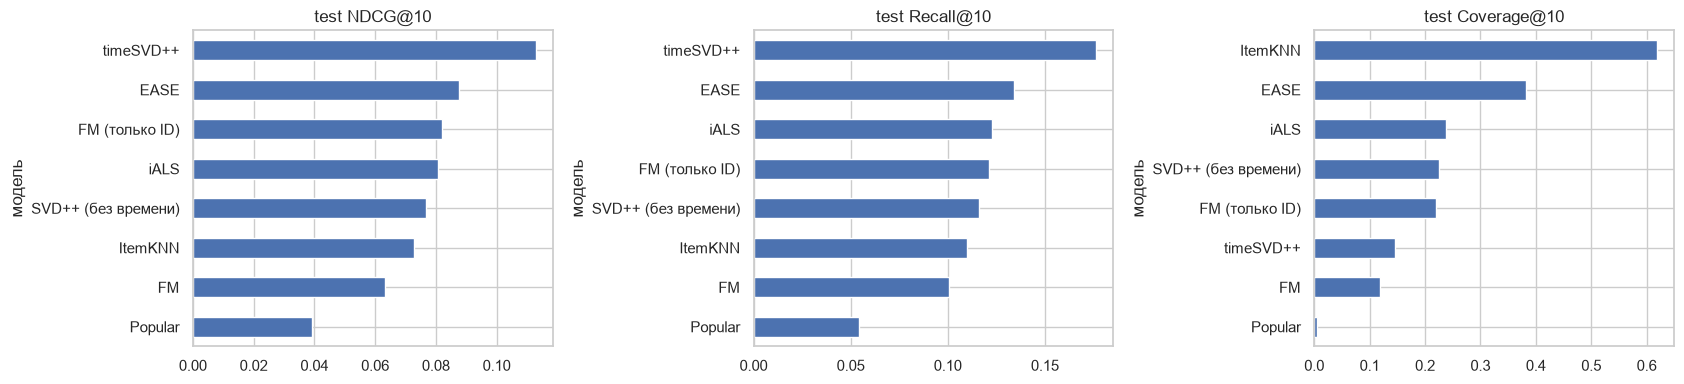

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, mname in zip(ax, ["NDCG@10", "Recall@10", "Coverage@10"]):
    res["test " + mname].sort_values().plot.barh(ax=a, title="test " + mname)
plt.tight_layout(); plt.show()

RMSE на test при neg_ratio=0 (остальные параметры - лучшие):

In [19]:
rm = {}
for name, ut in [("timeSVD++", True), ("SVD++ (без времени)", False)]:
    p = dict(best_params[name], neg_ratio=0)
    m = TimeSVDpp(use_time=ut, **p).fit(st)
    rm[name] = {"test RMSE": m.rmse(st, test), **evaluate(m, st)}
mu = st.train.rating.mean()
tt = test[test.user_id.isin(st.uid) & test.book_id.isin(st.iid)]
rm["константа mu"] = {"test RMSE": np.sqrt(((tt.rating - mu) ** 2).mean())}
pd.DataFrame(rm).T.round(4)

,test RMSE,NDCG@10,Recall@10,Coverage@10
timeSVD++,0.9846,0.0007,0.0011,0.2886
SVD++ (без времени),0.9556,0.0077,0.0112,0.5069
константа mu,1.0199,NaN,NaN,NaN


In [20]:
# медианная популярность рекомендованных книг
pop = np.asarray(st.X.sum(0)).ravel()
from models.metrics import top_k
pop_rec = {n: np.median(pop[top_k(m, st, st.eval_users)]) for n, m in final.items()}
pop_rec["(релевантные книги test)"] = np.median([pop[i] for u in st.eval_users for i in st.gt[u]])
pd.Series(pop_rec).round(0)

Popular                     6774.0
ItemKNN                     1262.0
iALS                         485.0
EASE                        1262.0
FM                          2654.0
FM (только ID)              2738.0
timeSVD++                   1081.0
SVD++ (без времени)         1434.0
(релевантные книги test)     106.0
dtype: float32

## 6. Выводы

Test:

| Модель | NDCG@10 | Recall@10 |
|---|---|---|
| timeSVD++ | 0.113 | 0.176 |
| EASE | 0.088 | 0.134 |
| FM (только ID) | 0.082 | 0.121 |
| iALS | 0.081 | 0.123 |
| SVD++ (без времени) | 0.077 | 0.116 |
| ItemKNN | 0.073 | 0.110 |
| FM | 0.063 | 0.101 |
| Popular | 0.039 | 0.054 |

Порядок на validation почти тот же.

Модели:
- timeSVD++ лучшая (+29% NDCG к EASE), но только с neg_ratio > 0: при 0 NDCG <= 0.005, хуже Popular. Оптимум - 8
- EASE - лучшая из простых: один параметр (lambda = 50, внутри сетки), сильнее kNN
- kNN - максимальное покрытие (62% против 12-38%). Лучший shrink = 0: после k-core редких пар почти нет
- iALS ~ FM-ID, рекомендует самые нишевые книги (медиана популярности 485 против ~1100-2700)

Время. timeSVD++ против SVD++: 0.113 против 0.077 на test (+47%). Гипотеза: $b_{i,\mathrm{Bin}(t)}$ последнего бина отражает текущую популярность. По RMSE (neg_ratio = 0) время не помогло: 0.985 против 0.956 (константа 1.020), но параметры подбирались под ранжирование.

Метаданные ухудшили FM: 0.063 против 0.082, покрытие 12% против 22%. Вероятно: после k-core ID-эмбеддинги и так обучены, а холодные книги, где признаки полезны, в оценку не входят; полки шумные; общие признаки (язык, формат) сглаживают персонализацию.

Ограничения:
- Один временной срез, без доверительных интервалов; близкие модели (iALS, FM-ID) не различимы
- k-core по всем данным до разбиения
- Холодные пользователи (28% строк test) и книги (6.5%) не оцениваются
- Не используются книги на полках без оценки (55% данных)
- 15 испытаний; iALS и FM упёрлись в размерность 128
- popular_shelves собраны в 2017 и могут слегка отражать будущее